# Variable objetivo y modelo baseline

En este notebook se define la variable objetivo y se establece un modelo *baseline* para futuras comparaciones.

1. **Variable objetivo**: construcción, distribución, balance y sesgos.
2. **Baseline**: primer modelo y resultados del primer entrenamiento.

Usa la base integrada `datos/datos_final/denue_coneval_iter_2020.csv` (2,469 municipios × 100 columnas) y el Marco Geoestadístico 2020 en `datos/datos_final/marco_geo/` (capas de municipios y estados) para los mapas.

Al final de la sección 2 se guarda la **base V2** (`datos/datos_final/denue_coneval_iter_2020_v2.csv`), que ya incluye la variable objetivo y no tiene las columnas con las que ésta se construye.

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle
import pandas as pd
from matplotlib.ticker import PercentFormatter

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score,
    classification_report, f1_score, mean_absolute_error, precision_score, r2_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
FIG_DIR = Path("figuras/entrega2")
FIG_DIR.mkdir(parents=True, exist_ok=True)

### Estilo de las gráficas

Una paleta fija para todo el notebook: **azul = accesibilidad adecuada**, **naranja = baja accesibilidad**. Es un par validado para daltonismo, y el texto va siempre en gris o negro, nunca en el color de la serie.

In [2]:
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, TINTA_3, REJILLA = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA_3, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", facecolor="white")

## 1. Carga de datos

In [3]:
df = pd.read_csv("datos/datos_final/denue_coneval_iter_2020.csv", dtype={"inegi_code": str})
assert df.shape == (2469, 100)
assert df["inegi_code"].is_unique
df.shape

(2469, 100)

**Denominador de población.** Siguiendo la nota del `README`, se usa la población del Censo (ITER: `POBFEM + POBMAS`) y no la de CONEVAL, que es una estimación calibrada a nivel estatal. La población del ITER, además, no tiene faltantes.

In [4]:
df["pobtot"] = df["POBFEM"] + df["POBMAS"]
assert df["pobtot"].gt(0).all()
df["pobtot"].describe().round(0)

count       2469.0
mean       51038.0
std       146991.0
min           81.0
25%         4489.0
50%        13552.0
75%        35284.0
max      1922523.0
Name: pobtot, dtype: float64

## 2. Variable objetivo

### 2.1 Conteos por servicio

Se agregan las columnas `act_<SCIAN>_per_<estrato>` del DENUE en los 4 servicios definidos en la entrega 1. Cada columna es un conteo de establecimientos por código SCIAN y estrato de personal ocupado.

In [5]:
SERVICIOS = {
    "farmacias":     ["464111", "464112"],
    "supermercados": ["462111"],
    "guarderias":    ["624411", "624412"],
    "consultorios":  ["621111", "621113"],
}
ETIQUETAS = {"farmacias": "Farmacias", "supermercados": "Supermercados",
             "guarderias": "Guarderías", "consultorios": "Consultorios"}

cols_act = [c for c in df.columns if c.startswith("act_")]
conteos = pd.DataFrame({
    s: df[[c for c in cols_act if c.split("_")[1] in codigos]].sum(axis=1)
    for s, codigos in SERVICIOS.items()
})
# Validación contra el total consolidado del README (144,272 establecimientos)
assert conteos.to_numpy().sum() == 144_272
conteos.sum().rename("establecimientos").to_frame()

,establecimientos
farmacias,62625
supermercados,6482
guarderias,10851
consultorios,64314


### 2.2 Tasas por 10,000 habitantes

In [6]:
tasas = conteos.div(df["pobtot"], axis=0) * 1e4
tasas.describe(percentiles=[.25, .5, .75, .9, .99]).T.round(2).assign(
    pct_ceros=(tasas.eq(0).mean() * 100).round(1)
)

,count,mean,std,min,25%,50%,75%,90%,99%,max,pct_ceros
farmacias,2469.0,4.63,3.88,0.0,2.2,4.08,6.39,8.94,17.73,40.16,15.3
supermercados,2469.0,0.19,0.69,0.0,0.0,0.00,0.20,0.61,1.65,23.20,71.7
guarderias,2469.0,0.46,0.73,0.0,0.0,0.00,0.73,1.33,2.94,11.06,53.8
consultorios,2469.0,2.65,3.09,0.0,0.0,1.91,3.94,6.30,13.11,28.76,30.4


**Desviación respecto a la entrega 1.** Ahí se propuso medir las guarderías por cada 10,000 niños de 0–4 años. La base final no trae la población de 0–4 años (del ITER sólo se integraron `POBFEM`, `POBMAS`, `P3YM_HLI` y `GRAPROES_*`), así que, por ahora, las guarderías también se miden por cada 10,000 habitantes. Si se agregan `P_0A2` y `P_3A5` del ITER, la tasa se puede corregir sin cambiar el resto del flujo.

### 2.3 ¿Por qué no usar la suma simple de tasas?

La entrega 1 proponía sumar las cuatro tasas. El problema es que las escalas son muy distintas: en un municipio típico hay unas 5 farmacias por cada 10 mil habitantes, pero apenas 0.2 supermercados. Con la suma simple, el índice sería casi un índice de farmacias y consultorios.

In [7]:
suma_simple = tasas.sum(axis=1)
aporte_suma = (tasas.mean() / suma_simple.mean() * 100).round(1)
aporte_suma.rename("% del índice (suma simple)").to_frame()

,% del índice (suma simple)
farmacias,58.4
supermercados,2.4
guarderias,5.8
consultorios,33.4


### 2.4 Índice de accesibilidad normalizado (IA)

Para cada servicio *k* y municipio *m*:

$$r_{mk} = \frac{\text{tasa}_{mk}}{\text{tasa nacional}_k}, \qquad \text{IA}_m = \frac{1}{4}\sum_{k} \min\left(r_{mk},\, P_{99}(r_{k})\right)$$

- **Normalizar por la tasa nacional** pone los cuatro servicios en la misma escala. Se lee así: IA = 1 significa que el municipio tiene, en promedio, la misma densidad de servicios que el país.
- **Winsorizar en el percentil 99** es el tratamiento de valores atípicos. Hay municipios muy pequeños donde un solo establecimiento dispara la tasa (por ejemplo, un supermercado en un municipio de 431 habitantes da 45 veces la tasa nacional). Recortar en el p99 evita que un solo servicio domine el índice de ese municipio.

In [8]:
tasa_nacional = conteos.sum() / df["pobtot"].sum() * 1e4
razon = tasas / tasa_nacional
p99 = razon.quantile(0.99)
razon_w = razon.clip(upper=p99, axis=1)

df["ia"] = razon_w.mean(axis=1)

aporte_ia = (razon_w.mean() / razon_w.mean().sum() * 100).round(1)
pd.DataFrame({
    "tasa nacional /10k": tasa_nacional.round(2),
    "p99 de la razón": p99.round(2),
    "% del índice (suma simple)": aporte_suma,
    "% del índice (IA)": aporte_ia,
})

,tasa nacional /10k,p99 de la razón,% del índice (suma simple),% del índice (IA)
farmacias,4.97,3.57,58.4,40.7
supermercados,0.51,3.21,2.4,14.1
guarderias,0.86,3.41,5.8,22.7
consultorios,5.10,2.57,33.4,22.5


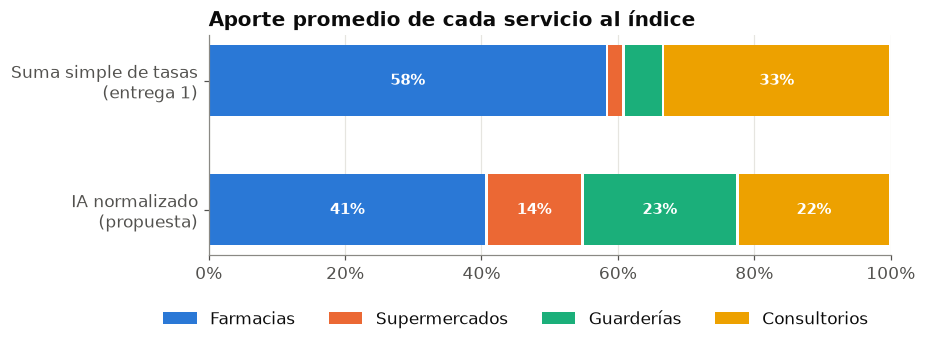

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.6))
colores = [AZUL, NARANJA, AQUA, AMARILLO]
filas = {"Suma simple de tasas\n(entrega 1)": aporte_suma, "IA normalizado\n(propuesta)": aporte_ia}
for i, (nombre, aporte) in enumerate(filas.items()):
    izq = 0
    for s, color in zip(SERVICIOS, colores):
        v = aporte[s]
        ax.barh(i, v - 0.4, left=izq + 0.2, color=color, height=0.55,
                label=ETIQUETAS[s] if i == 0 else None)
        if v >= 6:
            ax.text(izq + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white",
                    fontsize=10, fontweight="bold")
        izq += v
ax.set_yticks(range(len(filas)), list(filas))
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("Aporte promedio de cada servicio al índice")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.45, -0.18))
guardar(fig, "01_aporte_componentes")
plt.show()

### 2.5 Municipios sin cobertura del DENUE (falsos ceros)

Cuatro municipios de creación reciente tienen población en el Censo 2020 pero **ningún establecimiento** en el DENUE de noviembre de 2020. El caso más claro es San Quintín, con casi 118 mil habitantes. Lo más probable es que el DENUE todavía asignara sus establecimientos al municipio del que se separaron (San Quintín → Ensenada). Su IA = 0 sería un error de los datos, no falta real de servicios.

Por eso se **excluyen de la variable objetivo**: quedan como "sin dato" en los mapas y fuera del modelo. Seybaplaya y Honduras de la Sierra ya quedaban fuera del modelo por no tener estimación de pobreza de CONEVAL.

*Efecto secundario:* el municipio del que se separaron cuenta los establecimientos de ambos, pero sólo su propia población, así que su IA queda algo inflado (por ejemplo, Ensenada).

In [10]:
MUN_SIN_COBERTURA_DENUE = {
    "02006": "San Quintín (de Ensenada)",
    "04012": "Seybaplaya (de Champotón)",
    "07125": "Honduras de la Sierra (de Siltepec)",
    "17036": "Hueyapan (de Tetela del Volcán)",
}
excluir = df["inegi_code"].isin(MUN_SIN_COBERTURA_DENUE)
assert excluir.sum() == 4 and (~df.loc[excluir, "en_denue"]).all()  # todos sin ningún registro en el DENUE
excluidos = df.loc[excluir, ["inegi_code", "entidad", "municipio", "pobtot"]].copy()
display(excluidos)

df = df.loc[~excluir].reset_index(drop=True)
print(f"Municipios con variable objetivo: {len(df)}")

,inegi_code,entidad,municipio,pobtot
16,02006,Baja California,San Quintín,117568
33,04012,Campeche,Seybaplaya,15297
205,07125,Chiapas,Honduras de la Sierra,11650
937,17036,Morelos,Hueyapan,7855


Municipios con variable objetivo: 2465


### 2.6 Variable objetivo binaria: `baja_accesibilidad`

Para la clasificación (árbol + modelo lineal, como se planteó en la entrega 1), se define:

$$\texttt{baja\_accesibilidad}_m = \mathbb{1}\left[\text{IA}_m < 0.2\right]$$

Es decir, municipios con **menos de una quinta parte de la densidad nacional** de servicios esenciales. El umbral es absoluto y fácil de interpretar, y coincide casi exactamente con el cuartil inferior del IA. El IA continuo se conserva como objetivo alternativo para regresión.

In [11]:
UMBRAL = 0.2
df["baja_accesibilidad"] = (df["ia"] < UMBRAL).astype(int)

print(f"Cuartil inferior del IA: {df['ia'].quantile(0.25):.3f}")
print(df["ia"].describe(percentiles=[.1, .25, .5, .75, .9]).round(3).to_string())
df["baja_accesibilidad"].value_counts().to_frame("municipios").assign(
    pct=lambda t: (t["municipios"] / t["municipios"].sum() * 100).round(1)
)

Cuartil inferior del IA: 0.204
count    2465.000
mean        0.566
std         0.449
min         0.000
10%         0.000
25%         0.204
50%         0.493
75%         0.864
90%         1.176
max         2.666


,municipios,pct
baja_accesibilidad,,
0,1855,75.3
1,610,24.7


### 2.7 Distribución del IA

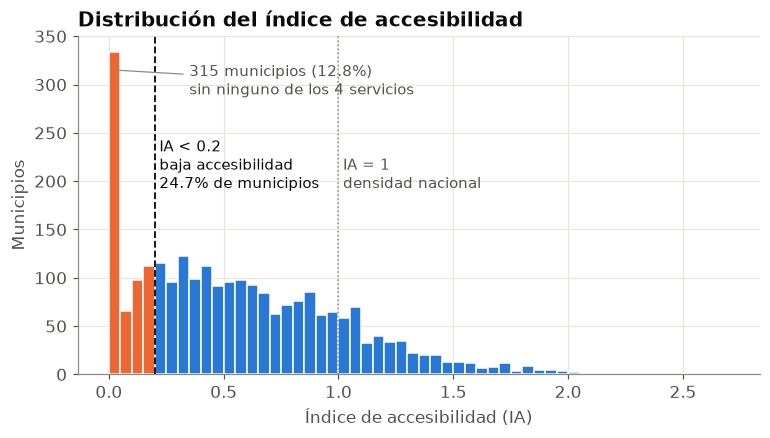

Media 0.57 · mediana 0.49 · desv. est. 0.45 · asimetría 0.79


In [12]:
n_cero = df["ia"].eq(0).sum()
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, df["ia"].max() + 0.05, 0.05)
_, b, parches = ax.hist(df["ia"], bins=bins, color=AZUL, edgecolor="white", linewidth=1)
for p, izq in zip(parches, b[:-1]):
    if izq < UMBRAL:
        p.set_facecolor(NARANJA)
ax.axvline(UMBRAL, color=TINTA, linewidth=1.2, linestyle="--")
ax.axvline(1, color=TINTA_3, linewidth=1, linestyle=":")
ax.annotate(f"{n_cero} municipios ({n_cero / len(df):.1%})\nsin ninguno de los 4 servicios",
            xy=(0.025, n_cero), xytext=(0.35, n_cero * 0.92), color=TINTA_2, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=TINTA_3, linewidth=0.8))
ax.text(UMBRAL + 0.02, ax.get_ylim()[1] * 0.55,
        f"IA < {UMBRAL}\nbaja accesibilidad\n{df['baja_accesibilidad'].mean():.1%} de municipios",
        color=TINTA, fontsize=10)
ax.text(1.02, ax.get_ylim()[1] * 0.55, "IA = 1\ndensidad nacional", color=TINTA_2, fontsize=10)
ax.set_xlabel("Índice de accesibilidad (IA)")
ax.set_ylabel("Municipios")
ax.set_title("Distribución del índice de accesibilidad")
guardar(fig, "02_distribucion_ia")
plt.show()

print(f"Media {df['ia'].mean():.2f} · mediana {df['ia'].median():.2f} · desv. est. {df['ia'].std():.2f} "
      f"· asimetría {df['ia'].skew():.2f}")

**Lectura.** El IA tiene asimetría positiva (media mayor que la mediana) y un **pico en cero**: 315 municipios (12.8%) no tienen ningún establecimiento de los cuatro servicios en el DENUE. Son los que tienen `en_denue = False`, menos los 4 municipios nuevos que se excluyeron. La mediana del municipio (≈0.49) queda por debajo de 1 porque la tasa nacional está dominada por las ciudades.

**Balance.** La clase positiva representa ~25% de los municipios (relación 1:3). Es un desbalance moderado: no impide entrenar, pero sí obliga a no usar *accuracy* como métrica principal (un modelo que siempre dice "no" ya tiene 75%) y a usar `class_weight="balanced"` y particiones estratificadas.

### 2.8 Sesgos de la variable objetivo

#### a) Tamaño de población: ruido de números pequeños

En un municipio de 500 habitantes, la tasa sólo puede valer 0, 20, 40… por cada 10 mil. Un establecimiento de más o de menos mueve mucho el índice. Por eso los municipios pequeños se concentran en los extremos: muchos en cero y algunos con los IA más altos del país.

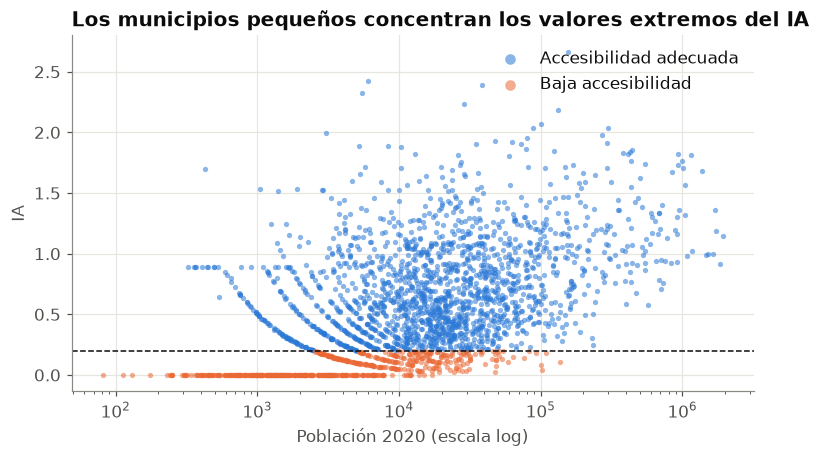

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for clase, color, nombre in [(0, AZUL, "Accesibilidad adecuada"), (1, NARANJA, "Baja accesibilidad")]:
    sub = df[df["baja_accesibilidad"] == clase]
    ax.scatter(sub["pobtot"], sub["ia"], s=12, color=color, alpha=0.55, linewidths=0, label=nombre)
ax.set_xscale("log")
ax.axhline(UMBRAL, color=TINTA, linewidth=1, linestyle="--")
ax.set_xlabel("Población 2020 (escala log)")
ax.set_ylabel("IA")
ax.set_title("Los municipios pequeños concentran los valores extremos del IA")
ax.legend(loc="upper right", markerscale=2)
guardar(fig, "03_ia_vs_poblacion")
plt.show()

In [14]:
quintil = pd.qcut(df["pobtot"], 5)
por_quintil = df.groupby(quintil, observed=True).agg(
    municipios=("ia", "size"),
    pob_min=("pobtot", "min"), pob_max=("pobtot", "max"),
    pct_baja=("baja_accesibilidad", "mean"),
    ia_media=("ia", "mean"), ia_desv=("ia", "std"),
)
por_quintil["pct_baja"] = (por_quintil["pct_baja"] * 100).round(1)
por_quintil.round(2)

,municipios,pob_min,pob_max,pct_baja,ia_media,ia_desv
pobtot,,,,,,
"(80.999, 3417.2]",493,81,3414,57.2,0.27,0.36
"(3417.2, 9154.6]",493,3418,9148,32.3,0.45,0.41
"(9154.6, 19243.0]",493,9159,19219,20.3,0.54,0.37
"(19243.0, 45386.0]",493,19279,45373,9.9,0.66,0.41
"(45386.0, 1922523.0]",493,45438,1922523,4.1,0.90,0.43


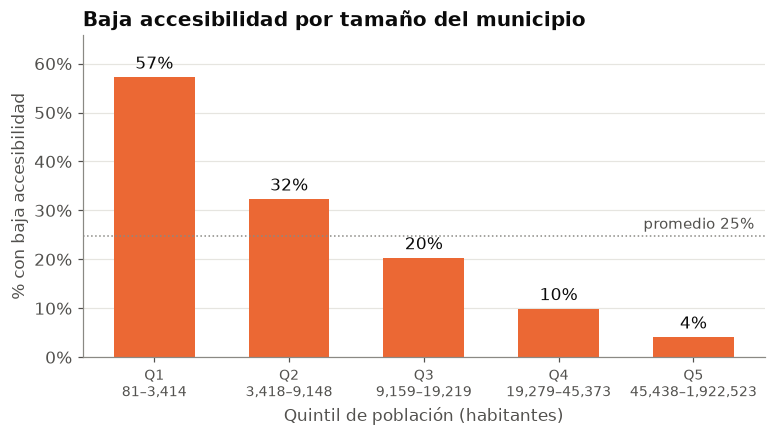

In [15]:
etiquetas_q = [f"Q{i + 1}\n{int(r.pob_min):,}–{int(r.pob_max):,}" for i, r in enumerate(por_quintil.itertuples())]
fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.bar(range(5), por_quintil["pct_baja"], color=NARANJA, width=0.6)
ax.bar_label(barras, labels=[f"{v:.0f}%" for v in por_quintil["pct_baja"]], padding=3, color=TINTA)
ax.axhline(df["baja_accesibilidad"].mean() * 100, color=TINTA_3, linewidth=1, linestyle=":")
ax.text(4.45, df["baja_accesibilidad"].mean() * 100 + 1.5, "promedio 25%", color=TINTA_2, ha="right", fontsize=10)
ax.set_xticks(range(5), etiquetas_q, fontsize=9)
ax.set_ylim(0, por_quintil["pct_baja"].max() * 1.15)
ax.set_xlabel("Quintil de población (habitantes)")
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_ylabel("% con baja accesibilidad")
ax.grid(axis="x", visible=False)
ax.set_title("Baja accesibilidad por tamaño del municipio")
guardar(fig, "04_baja_por_quintil_poblacion")
plt.show()

In [16]:
pob_baja = df.loc[df["baja_accesibilidad"] == 1, "pobtot"].sum() / df["pobtot"].sum()
print(f"Municipios con baja accesibilidad: {df['baja_accesibilidad'].mean():.1%} de los municipios, "
      f"pero sólo {pob_baja:.1%} de la población.")

Municipios con baja accesibilidad: 24.7% de los municipios, pero sólo 4.3% de la población.


**Implicación.** Una cuarta parte de los municipios tiene baja accesibilidad, pero ahí vive menos del 5% de la población. El análisis es **por municipio, no por persona**, y hay que decirlo así en la interpretación. Para el reporte final se puede probar un suavizado bayesiano empírico de las tasas (acercar las tasas de municipios pequeños a la media estatal) o ponderar por población.

#### b) Concentración geográfica

Oaxaca tiene 570 de los 2,465 municipios con variable objetivo (23%), y casi todos son pequeños. Así que la clase positiva está muy cargada hacia un solo estado.

In [17]:
por_entidad = df.groupby("entidad").agg(municipios=("ia", "size"), positivos=("baja_accesibilidad", "sum"))
por_entidad["pct_baja"] = (por_entidad["positivos"] / por_entidad["municipios"] * 100).round(1)
por_entidad["pct_de_positivos"] = (por_entidad["positivos"] / por_entidad["positivos"].sum() * 100).round(1)
por_entidad.sort_values("positivos", ascending=False).head(10)

,municipios,positivos,pct_baja,pct_de_positivos
entidad,,,,
Oaxaca,570,274,48.1,44.9
Veracruz de Ignacio de la Llave,212,51,24.1,8.4
Puebla,217,48,22.1,7.9
Yucatán,106,40,37.7,6.6
Chiapas,123,27,22.0,4.4
Chihuahua,67,23,34.3,3.8
San Luis Potosí,58,20,34.5,3.3
Guerrero,81,18,22.2,3.0
Sonora,72,17,23.6,2.8


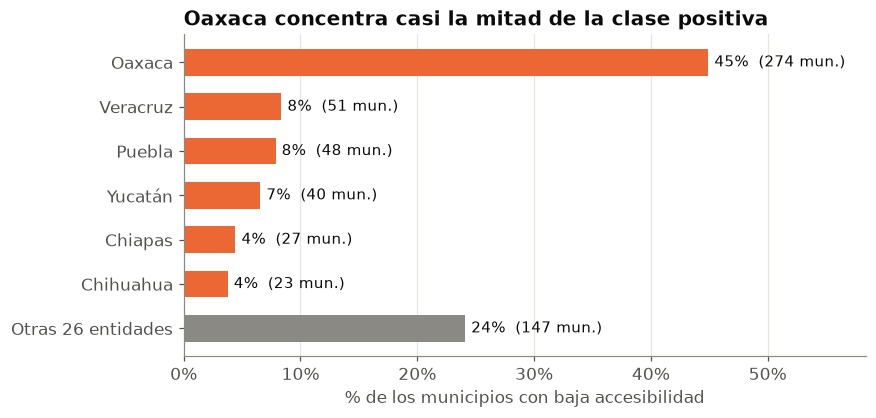

In [18]:
top = por_entidad.sort_values("positivos", ascending=False)
mostrar = top.head(6).copy()
mostrar.loc["Otras 26 entidades"] = top.iloc[6:].sum(numeric_only=True)
mostrar["pct_de_positivos"] = mostrar["positivos"] / mostrar["positivos"].sum() * 100
mostrar = mostrar.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 3.8))
colores_e = [TINTA_3 if i == "Otras 26 entidades" else NARANJA for i in mostrar.index]
barras = ax.barh(mostrar.index.str.replace(" de Ignacio de la Llave", "").str.replace(" de Ocampo", ""),
                 mostrar["pct_de_positivos"], color=colores_e, height=0.6)
ax.bar_label(barras, labels=[f"{p:.0f}%  ({int(n)} mun.)" for p, n in zip(mostrar["pct_de_positivos"], mostrar["positivos"])],
             padding=4, color=TINTA, fontsize=10)
ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_xlim(0, mostrar["pct_de_positivos"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de los municipios con baja accesibilidad")
ax.set_title("Oaxaca concentra casi la mitad de la clase positiva")
guardar(fig, "05_positivos_por_entidad")
plt.show()

**Implicación.** Un modelo puede aprender "parece Oaxaca" en vez de "es pobre". Además, los municipios vecinos se parecen entre sí, así que una partición aleatoria deja información de un estado tanto en entrenamiento como en prueba. En el baseline se mide esto con una validación cruzada agrupada por entidad (`GroupKFold`).

#### c) Sesgos de medición (cobertura del DENUE y definición de servicios)

Estos sesgos no se ven en las gráficas, pero afectan qué significa la variable objetivo:

| Sesgo | Efecto esperado sobre el IA |
| :--- | :--- |
| **Sólo consultorios privados** (621111, 621113). Quedan fuera los consultorios públicos (621112, 621114), los centros de salud de SSA/IMSS-Bienestar y los hospitales (622). | Subestima el acceso en municipios pobres y rurales, donde la oferta de salud es sobre todo pública. Es un sesgo **en la misma dirección** que la hipótesis: puede inflar la relación pobreza ↔ baja accesibilidad. |
| **Sólo supermercados** (462111). Quedan fuera tiendas de abarrotes (461110), minisúper (462112), mercados públicos y tianguis. | En zonas rurales el abasto pasa por abarrotes y mercados, así que el componente de supermercados mide sobre todo urbanización. |
| **El DENUE sólo registra establecimientos fijos.** No incluye comercio ambulante ni servicios informales. | Subestima la oferta en municipios con más informalidad, que suelen ser los más pobres. |
| **Límites municipales.** Se cuenta lo que está *dentro* del municipio, no lo que la gente usa. | En zonas metropolitanas la población usa servicios del municipio vecino (municipios "dormitorio" con IA bajo pero buen acceso real). |
| **Tasa por habitante, no por distancia.** | Un municipio extenso y disperso puede tener una buena tasa y aun así estar lejos de los servicios. La distancia queda como extensión (entrega 1). |
| **Guarderías por habitante total**, no por niños de 0–4 años. | Penaliza a los municipios con poblaciones más envejecidas y favorece a los más jóvenes. |
| **Corte noviembre 2020** (pandemia). | Algunos cierres temporales pueden no estar reflejados o estar sobre-reflejados. |

#### d) Sensibilidad al umbral

El umbral de 0.2 es una decisión. La tabla muestra cómo cambia el tamaño de la clase positiva con otros umbrales, y en el baseline se revisa que el desempeño no dependa de esa elección.

In [19]:
pd.DataFrame({
    "umbral": [0.1, 0.2, 0.33, 0.5],
    "% municipios": [round((df["ia"] < u).mean() * 100, 1) for u in [0.1, 0.2, 0.33, 0.5]],
    "% población": [round(df.loc[df["ia"] < u, "pobtot"].sum() / df["pobtot"].sum() * 100, 1) for u in [0.1, 0.2, 0.33, 0.5]],
})

,umbral,% municipios,% población
0,0.10,16.2,1.7
1,0.20,24.7,4.3
2,0.33,36.4,8.4
3,0.50,50.5,15.6


### 2.9 Distribución geográfica

Se usa el Marco Geoestadístico 2020 (`datos/datos_final/marco_geo/`: capas de municipios `00mun` y de estados `00ent`, copiadas sin cambios del INEGI), que ya viene en una proyección cónica conforme de Lambert para México. Las geometrías se simplifican (tolerancia de 250 m en municipios y 500 m en estados) sólo para dibujar más rápido. A esa escala la diferencia no se nota.

In [20]:
MARCO = Path("datos/datos_final/marco_geo")
municipios_geo = gpd.read_file(MARCO / "00mun.shp")[["CVEGEO", "geometry"]]
estados_geo = gpd.read_file(MARCO / "00ent.shp")[["CVE_ENT", "NOMGEO", "geometry"]]
municipios_geo["geometry"] = municipios_geo.geometry.simplify(250, preserve_topology=True)
estados_geo["geometry"] = estados_geo.geometry.simplify(500, preserve_topology=True)

mapa = municipios_geo.merge(df[["inegi_code", "entidad", "municipio", "pobtot", "ia", "baja_accesibilidad"]],
                            left_on="CVEGEO", right_on="inegi_code", how="left", validate="one_to_one")
assert len(mapa) == 2469 and mapa["CVEGEO"].isin(df["inegi_code"]).sum() == len(df)  # todas las claves cruzan
sin_dato = mapa["ia"].isna()
assert set(mapa.loc[sin_dato, "CVEGEO"]) == set(MUN_SIN_COBERTURA_DENUE)
print(mapa.crs.name)

BLANCO_SIN_DATO = "#ffffff"
def dibujar_sin_dato(ax, datos_mapa, ancho_mun):
    sd = datos_mapa[datos_mapa["ia"].isna()]
    if len(sd):
        sd.plot(ax=ax, color=BLANCO_SIN_DATO, edgecolor=TINTA_3, hatch="////", linewidth=max(ancho_mun, 0.3))
PARCHE_SIN_DATO = Patch(facecolor=BLANCO_SIN_DATO, edgecolor=TINTA_3, hatch="////",
                        label=f"Sin dato: municipio nuevo sin registros en el DENUE · {len(MUN_SIN_COBERTURA_DENUE)}")

MEXICO_ITRF_2008_LCC


#### a) Dónde están los municipios con baja accesibilidad

El recuadro amplía Oaxaca y Puebla. Ahí los municipios son tan pequeños que en el mapa nacional casi no se distinguen, aunque son la mayor parte de la clase positiva.

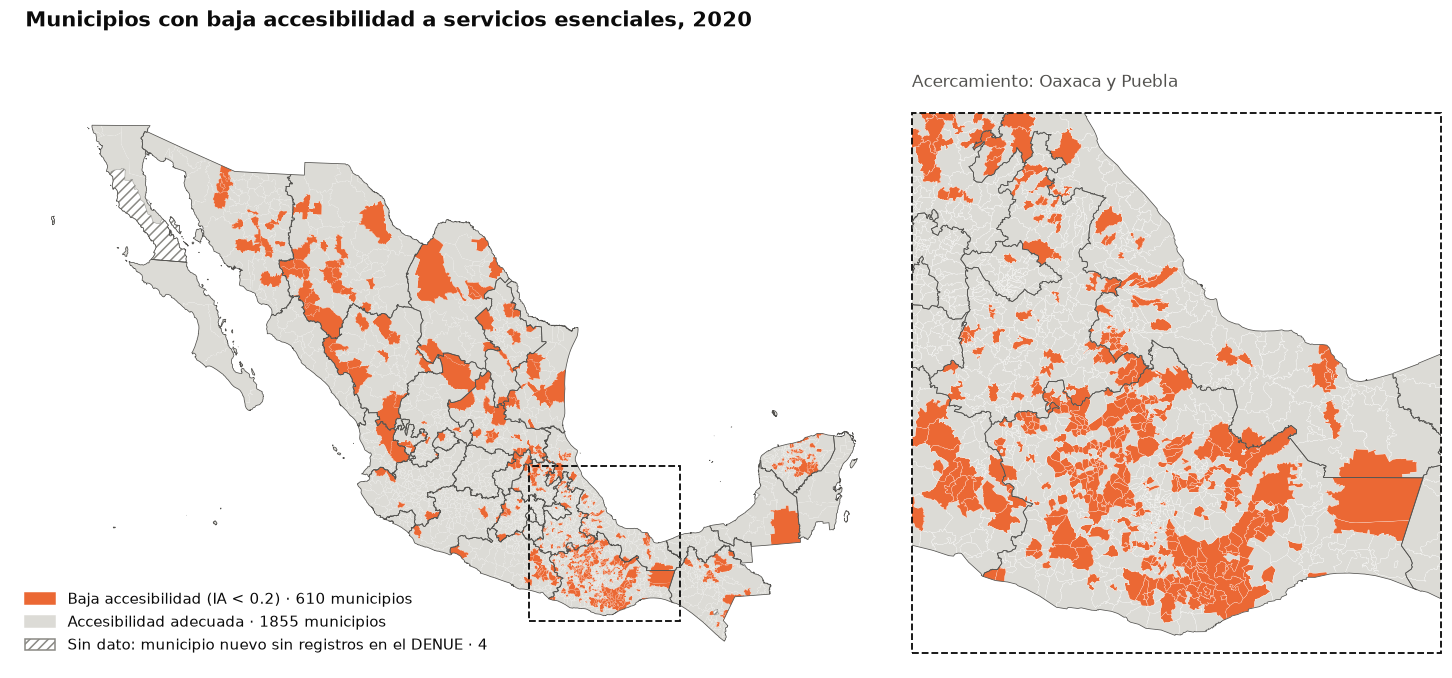

In [21]:
GRIS_FONDO, BORDE_EDO = "#dcdbd6", "#52514e"

def dibujar_binario(ax, datos_mapa, ancho_mun):
    con_dato = datos_mapa[datos_mapa["ia"].notna()]
    colores_bin = con_dato["baja_accesibilidad"].map({0: GRIS_FONDO, 1: NARANJA})
    con_dato.plot(ax=ax, color=colores_bin, edgecolor="white", linewidth=ancho_mun)
    dibujar_sin_dato(ax, datos_mapa, ancho_mun)
    estados_geo.boundary.plot(ax=ax, color=BORDE_EDO, linewidth=0.5)
    ax.set_axis_off()

# Recuadro: Oaxaca (20) y Puebla (21)
xmin, ymin, xmax, ymax = estados_geo[estados_geo["CVE_ENT"].isin(["20", "21"])].total_bounds
margen = 20_000
caja = (xmin - margen, ymin - margen, xmax + margen, ymax + margen)

fig = plt.figure(figsize=(13, 6.4))
ax_nac = fig.add_axes([0.0, 0.0, 0.62, 0.92])
ax_zoom = fig.add_axes([0.63, 0.06, 0.37, 0.80])

dibujar_binario(ax_nac, mapa, 0.05)
ax_nac.add_patch(Rectangle((caja[0], caja[1]), caja[2] - caja[0], caja[3] - caja[1],
                           fill=False, edgecolor=TINTA, linewidth=1.2, linestyle="--"))

en_caja = mapa.cx[caja[0]:caja[2], caja[1]:caja[3]]
dibujar_binario(ax_zoom, en_caja, 0.15)
ax_zoom.set_xlim(caja[0], caja[2])
ax_zoom.set_ylim(caja[1], caja[3])
ax_zoom.set_title("Acercamiento: Oaxaca y Puebla", fontsize=11, color=TINTA_2, fontweight="normal")
ax_zoom.add_patch(Rectangle((caja[0], caja[1]), caja[2] - caja[0], caja[3] - caja[1],
                            fill=False, edgecolor=TINTA, linewidth=1.2, linestyle="--", clip_on=False))

n_baja = int(df["baja_accesibilidad"].sum())
ax_nac.legend(handles=[Patch(color=NARANJA, label=f"Baja accesibilidad (IA < {UMBRAL}) · {n_baja} municipios"),
                       Patch(color=GRIS_FONDO, label=f"Accesibilidad adecuada · {len(df) - n_baja} municipios"),
                       PARCHE_SIN_DATO],
              loc="lower left", fontsize=10)
fig.suptitle("Municipios con baja accesibilidad a servicios esenciales, 2020", x=0.01, y=0.99,
             ha="left", fontsize=14, fontweight="bold")
guardar(fig, "09_mapa_baja_accesibilidad")
plt.show()

#### b) El índice continuo respecto a la densidad nacional

Escala divergente centrada en IA = 1 (densidad nacional): naranja por debajo, azul por arriba y gris cerca del promedio nacional. Los cortes son simétricos alrededor de 1 (±0.1, ±0.4, ±0.8), y el tramo naranja más intenso (IA < 0.2) es exactamente la clase `baja_accesibilidad`.

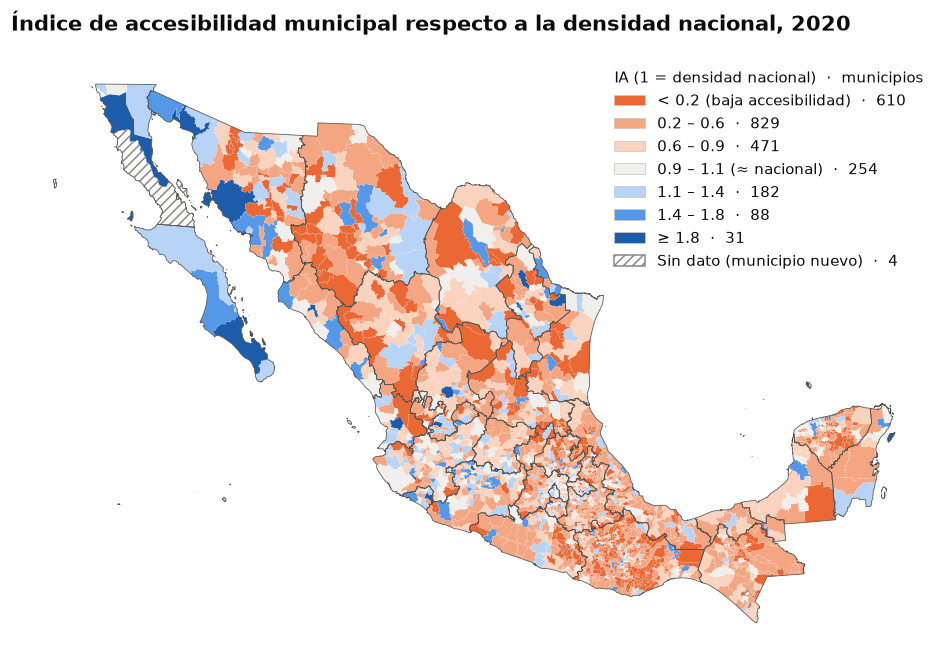

In [22]:
CORTES = [0, 0.2, 0.6, 0.9, 1.1, 1.4, 1.8, np.inf]
COLORES_IA = [NARANJA, "#f4a582", "#fad3bf", "#f0efec", "#b7d3f6", "#5598e7", "#1c5cab"]
ETQ_IA = ["< 0.2 (baja accesibilidad)", "0.2 – 0.6", "0.6 – 0.9", "0.9 – 1.1 (≈ nacional)", "1.1 – 1.4", "1.4 – 1.8", "≥ 1.8"]

mapa["ia_rango"] = pd.cut(mapa["ia"], CORTES, right=False, labels=ETQ_IA)
color_rango = dict(zip(ETQ_IA, COLORES_IA))

fig, ax = plt.subplots(figsize=(11, 7))
con_dato = mapa[~sin_dato]
con_dato.plot(ax=ax, color=con_dato["ia_rango"].map(color_rango).astype(str), edgecolor="white", linewidth=0.05)
dibujar_sin_dato(ax, mapa, 0.05)
estados_geo.boundary.plot(ax=ax, color=BORDE_EDO, linewidth=0.5)
ax.set_axis_off()
conteo = mapa["ia_rango"].value_counts()
ax.legend(handles=[Patch(facecolor=c, edgecolor="#c9c8c2", linewidth=0.5, label=f"{e}  ·  {conteo[e]:,}")
                   for e, c in zip(ETQ_IA, COLORES_IA)]
                  + [Patch(facecolor=BLANCO_SIN_DATO, edgecolor=TINTA_3, hatch="////",
                           label=f"Sin dato (municipio nuevo)  ·  {int(sin_dato.sum())}")],
          title="IA (1 = densidad nacional)  ·  municipios", title_fontsize=10, fontsize=10,
          loc="upper right", alignment="left")
ax.set_title("Índice de accesibilidad municipal respecto a la densidad nacional, 2020", fontsize=14)
guardar(fig, "10_mapa_ia")
plt.show()

In [23]:
# Resumen por región para leer los mapas: % de municipios con baja accesibilidad y % de población en ellos
REGIONES = {
    "Noroeste": ["Baja California", "Baja California Sur", "Sonora", "Sinaloa", "Chihuahua", "Durango"],
    "Noreste": ["Coahuila de Zaragoza", "Nuevo León", "Tamaulipas", "San Luis Potosí"],
    "Occidente": ["Jalisco", "Colima", "Nayarit", "Aguascalientes", "Zacatecas", "Michoacán de Ocampo"],
    "Centro": ["Ciudad de México", "México", "Hidalgo", "Morelos", "Puebla", "Tlaxcala", "Querétaro", "Guanajuato"],
    "Sur": ["Oaxaca", "Guerrero", "Chiapas", "Veracruz de Ignacio de la Llave"],
    "Península y Golfo": ["Yucatán", "Campeche", "Quintana Roo", "Tabasco"],
}
region = {e: r for r, lista in REGIONES.items() for e in lista}
assert set(df["entidad"]) == set(region)
df["region"] = df["entidad"].map(region)
(df.assign(pob_baja=df["pobtot"] * df["baja_accesibilidad"])
   .groupby("region")
   .agg(municipios=("ia", "size"), pct_baja=("baja_accesibilidad", "mean"), ia_mediana=("ia", "median"),
        pob=("pobtot", "sum"), pob_baja=("pob_baja", "sum"))
   .assign(pct_baja=lambda t: (t["pct_baja"] * 100).round(1),
           pct_pob_baja=lambda t: (t["pob_baja"] / t["pob"] * 100).round(1))
   .drop(columns=["pob", "pob_baja"])
   .sort_values("pct_baja", ascending=False)
   .round(2))

,municipios,pct_baja,ia_mediana,pct_pob_baja
region,,,,
Sur,986,37.5,0.31,13.9
Península y Golfo,145,28.3,0.42,2.7
Noreste,190,26.3,0.57,3.5
Noroeste,206,24.8,0.58,2.2
Centro,601,13.0,0.60,2.5
Occidente,337,5.9,0.78,1.0


**Lectura de los mapas.**

- La baja accesibilidad se concentra en el **sur** (Oaxaca, sierras de Guerrero, Chiapas y Veracruz), en la **península de Yucatán** (municipios rurales del interior) y en la **Sierra Tarahumara** (suroeste de Chihuahua). El Bajío, el Occidente y el centro del país están casi todos en el promedio nacional o por encima.
- **Hay un patrón espacial claro.** Los municipios con IA bajo tienden a tener vecinos con IA bajo. Esto confirma el riesgo de la partición aleatoria (información de los vecinos en entrenamiento y prueba) y es la razón de validar por entidad en el baseline.
- **Se ve el efecto de los municipios nuevos.** San Quintín aparece como "sin dato" y Ensenada, el municipio del que se separó, sale en el tramo más alto del IA (≥ 1.8). Eso es porque Ensenada cuenta los establecimientos de ambos, pero sólo su propia población (sección 2.5).
- **Ojo con la lectura visual.** En un mapa de coropletas, el área domina la percepción: los municipios grandes y poco poblados del norte pesan mucho a la vista, y los 570 municipios de Oaxaca casi no se ven a escala nacional (por eso el acercamiento). Es la misma advertencia del sesgo por tamaño: el mapa cuenta municipios, no personas.

### 2.10 Base V2: variable objetivo sin fuga de información

Se guarda una versión 2 de la base con la variable objetivo, para que el resto del equipo (y el modelado) parta de aquí.

**Se eliminan las 45 columnas con las que se construye la variable objetivo:**

- Las 44 columnas `act_*` (conteos del DENUE). Con ellas se calcula directamente el IA.
- `en_denue`: si vale `False`, el IA es 0 y la etiqueta es 1 con seguridad.

**Se agregan** `ia` (objetivo continuo) y `baja_accesibilidad` (objetivo binario).

**Decisiones:**

- **La población (`POBFEM`, `POBMAS`) se conserva**, aunque es el denominador de las tasas. Se conoce sin consultar el DENUE y por sí sola no revela cuántos establecimientos hay, así que es un predictor legítimo. Su efecto se mide en el baseline (variante "+ log población").
- **Se conservan las 2,469 filas.** Los 4 municipios sin cobertura del DENUE (sección 2.5) quedan con `ia` y `baja_accesibilidad` vacíos, para poder usarlos en análisis que no dependen del objetivo (por ejemplo, clustering). Antes de modelar hay que filtrarlos.
- `ia` y `baja_accesibilidad` son dos versiones del mismo objetivo: **nunca se debe usar una como predictor de la otra.**

In [24]:
DIR_FINAL = Path("datos/datos_final")
RUTA_V2 = DIR_FINAL / "denue_coneval_iter_2020_v2.csv"

original = pd.read_csv(DIR_FINAL / "denue_coneval_iter_2020.csv", dtype={"inegi_code": str})
COLS_FUGA = [c for c in original.columns if c.startswith("act_")] + ["en_denue"]

objetivo = df[["inegi_code", "ia", "baja_accesibilidad"]]
v2 = (original.drop(columns=COLS_FUGA)
      .merge(objetivo, on="inegi_code", how="left", validate="one_to_one"))
v2["baja_accesibilidad"] = v2["baja_accesibilidad"].astype("Int64")

assert len(v2) == 2469 and len(COLS_FUGA) == 45
assert v2.shape[1] == original.shape[1] - 45 + 2
assert set(v2.loc[v2["ia"].isna(), "inegi_code"]) == set(MUN_SIN_COBERTURA_DENUE)
assert not any(c.startswith("act_") for c in v2.columns) and "en_denue" not in v2.columns

v2.to_csv(RUTA_V2, index=False, encoding="utf-8-sig")
v2.to_excel(RUTA_V2.with_suffix(".xlsx"), index=False)
print(f"{RUTA_V2}: {v2.shape[0]} filas × {v2.shape[1]} columnas")
v2[["inegi_code", "entidad", "municipio", "ia", "baja_accesibilidad"]].head()

datos/datos_final/denue_coneval_iter_2020_v2.csv: 2469 filas × 57 columnas


,inegi_code,entidad,municipio,ia,baja_accesibilidad
0,01001,Aguascalientes,Aguascalientes,1.361848,0
1,01002,Aguascalientes,Asientos,0.306611,0
2,01003,Aguascalientes,Calvillo,0.547279,0
3,01004,Aguascalientes,Cosío,0.235175,0
4,01005,Aguascalientes,Jesús María,0.851253,0


Diccionario de datos de la V2: se parte del diccionario original, se quitan las columnas eliminadas, se recalculan los faltantes y se documentan las dos columnas nuevas.

In [25]:
dicc = pd.read_excel(DIR_FINAL / "diccionario_datos.xlsx")
dicc = dicc[~dicc["variable"].isin(COLS_FUGA)].copy()
sin_cob = ", ".join(sorted(MUN_SIN_COBERTURA_DENUE))
nuevas = pd.DataFrame([
    {"variable": "ia", "fuente": "Derivada (DENUE + ITER)", "tipo": "float64",
     "descripcion": ("VARIABLE OBJETIVO (continua). Índice de accesibilidad a servicios esenciales: promedio, sobre "
                     "farmacias (464111, 464112), supermercados (462111), guarderías (624411, 624412) y consultorios "
                     "privados (621111, 621113), de la tasa por 10,000 hab. (población ITER: POBFEM + POBMAS) "
                     "dividida entre la tasa nacional y recortada en su percentil 99. 1 = densidad nacional. "
                     f"Vacía en los municipios nuevos sin cobertura del DENUE ({sin_cob}).")},
    {"variable": "baja_accesibilidad", "fuente": "Derivada (DENUE + ITER)", "tipo": "Int64",
     "descripcion": (f"VARIABLE OBJETIVO (binaria). 1 si ia < {UMBRAL} (menos de una quinta parte de la densidad "
                     f"nacional de servicios); 0 en otro caso. Vacía en los mismos municipios que ia. "
                     "No usar ia como predictor de esta variable.")},
])
dicc_v2 = pd.concat([dicc, nuevas], ignore_index=True)
dicc_v2["n_faltantes"] = dicc_v2["variable"].map(v2.isna().sum())
assert list(dicc_v2["variable"]) == list(v2.columns)

ruta_dicc = DIR_FINAL / "diccionario_datos_v2.xlsx"
with pd.ExcelWriter(ruta_dicc, engine="openpyxl") as xls:
    dicc_v2.to_excel(xls, index=False, sheet_name="diccionario_datos")
    hoja = xls.sheets["diccionario_datos"]
    for col, ancho in zip("ABCDE", [44, 24, 110, 10, 12]):
        hoja.column_dimensions[col].width = ancho
    hoja.freeze_panes = "B2"
print(ruta_dicc)
dicc_v2.tail(4)

datos/datos_final/diccionario_datos_v2.xlsx


,variable,fuente,descripcion,tipo,n_faltantes
53,GRAPROES_F,ITER (Censo 2020),Grado promedio de escolaridad de la población ...,float64,0
54,GRAPROES_M,ITER (Censo 2020),Grado promedio de escolaridad de la población ...,float64,0
55,ia,Derivada (DENUE + ITER),VARIABLE OBJETIVO (continua). Índice de accesi...,float64,4
56,baja_accesibilidad,Derivada (DENUE + ITER),VARIABLE OBJETIVO (binaria). 1 si ia < 0.2 (me...,Int64,4


## 3. Baseline

### 3.1 Datos para el modelo

- **Fuente.** El modelado lee la **base V2** (sección 2.10), que no tiene las columnas `act_*` ni `en_denue`. Así se garantiza que el modelo no vea la información con la que se construye la variable objetivo.
- **Filas.** Se quitan los 4 municipios sin variable objetivo (sección 2.5) y los municipios sin estimación de pobreza de CONEVAL. Son 3 en la base (Seybaplaya, Honduras de la Sierra y La Magdalena Tlaltelulco), pero los dos primeros ya se habían excluido por no tener cobertura del DENUE (sección 2.5), así que aquí sólo sale La Magdalena Tlaltelulco. Son faltantes documentados por muestra insuficiente y no se imputan. En total, el modelo usa 2,464 de los 2,469 municipios.
- **Predictores del baseline.** Indicadores socioeconómicos en porcentaje de CONEVAL, más escolaridad y % de hablantes de lengua indígena del Censo. Se excluyen:
  - `ia`, porque es la versión continua del mismo objetivo.
  - Las columnas `personas_*`, porque son conteos que replican la población.
  - `pct_no_pobre_no_vulnerable` y `pct_pobreza_moderada`, que son combinaciones lineales de otras.
- La selección final de variables viene del apartado de variables predictoras. Aquí se usa un conjunto amplio a propósito, como primer intento.

In [26]:
base = pd.read_csv(RUTA_V2, dtype={"inegi_code": str})
assert not any(c.startswith("act_") for c in base.columns) and "en_denue" not in base.columns
base = base.dropna(subset=["baja_accesibilidad"])  # 4 municipios sin cobertura del DENUE

base["pobtot"] = base["POBFEM"] + base["POBMAS"]
base["escolaridad"] = (base["GRAPROES_F"] + base["GRAPROES_M"]) / 2
base["pct_hli"] = base["P3YM_HLI"] / base["pobtot"] * 100
base["log_pob"] = np.log10(base["pobtot"])

SOCIO = [
    "pct_pobreza", "pct_pobreza_extrema", "pct_vulnerable_carencia_social", "pct_vulnerable_ingreso",
    "pct_rezago_educativo", "pct_carencia_salud", "pct_carencia_seguridad_social",
    "pct_carencia_calidad_vivienda", "pct_carencia_servicios_basicos_vivienda",
    "pct_carencia_alimentacion", "pct_ingreso_bajo_linea_pobreza", "escolaridad", "pct_hli",
]
CONJUNTOS = {
    "Sólo % pobreza": ["pct_pobreza"],
    "Socioeconómicas": SOCIO,
    "Socioeconómicas + log población": SOCIO + ["log_pob"],
}

datos = base.dropna(subset=SOCIO).reset_index(drop=True)
print(f"Se eliminan {len(base) - len(datos)} municipios sin datos de CONEVAL:",
      base.loc[base[SOCIO].isna().any(axis=1), "municipio"].tolist())
y = datos["baja_accesibilidad"].astype(int)
print(f"Municipios para modelar: {len(datos)} · % clase positiva: {y.mean():.1%}")

Se eliminan 1 municipios sin datos de CONEVAL: ['La Magdalena Tlaltelulco']
Municipios para modelar: 2464 · % clase positiva: 24.8%


### 3.2 Esquema de evaluación

- Partición **80/20 estratificada** (`random_state=42`). El 20% de prueba no se toca hasta el final.
- En entrenamiento: **validación cruzada estratificada de 5 pliegues**, para tener una media y una desviación de cada métrica.
- **Validación agrupada por entidad** (`GroupKFold`, 5 grupos de estados) como prueba de robustez geográfica: el modelo se evalúa en estados que no vio.
- **Métricas.** Por el desbalance 1:3, la métrica principal es **ROC-AUC**. También se reportan PR-AUC, F1, *recall* y precisión de la clase positiva y *balanced accuracy*. La *accuracy* sólo se incluye como referencia.

### 3.3 Modelos

| Modelo | Por qué |
| :--- | :--- |
| `DummyClassifier` (clase mayoritaria) | Piso: cualquier modelo útil tiene que superarlo. |
| Regresión logística (`StandardScaler` + `class_weight="balanced"`) | Modelo lineal *benchmark* que se planteó en la entrega 1. Es interpretable por sus coeficientes. |
| Árbol de decisión (profundidad 4, `class_weight="balanced"`) | Modelo no lineal más simple. Es el punto de partida de Random Forest y Gradient Boosting. |

Sin búsqueda de hiperparámetros: esto es el primer intento.

In [27]:
idx_train, idx_test = train_test_split(datos.index, test_size=0.2, stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]
print(f"Entrenamiento: {len(idx_train)} ({y_train.mean():.1%} positivos) · Prueba: {len(idx_test)} ({y_test.mean():.1%} positivos)")

def modelos():
    return {
        "Dummy (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
        "Regresión logística": Pipeline([
            ("escala", StandardScaler()),
            ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000)),
        ]),
        "Árbol de decisión (prof. 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    }

cv_estrat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_grupos = GroupKFold(n_splits=5)
METRICAS_CV = ["roc_auc", "average_precision", "f1", "balanced_accuracy"]

resultados, ajustados = [], {}
for nombre_x, cols in CONJUNTOS.items():
    for nombre_m, modelo in modelos().items():
        if nombre_m.startswith("Dummy") and nombre_x != "Sólo % pobreza":
            continue  # el dummy ignora las X: basta con evaluarlo una vez
        X = datos[cols]
        cv = cross_validate(modelo, X.loc[idx_train], y_train, cv=cv_estrat, scoring=METRICAS_CV)
        cvg = cross_validate(modelo, X, y, cv=cv_grupos, groups=datos["entidad"], scoring=["roc_auc", "f1"])
        modelo.fit(X.loc[idx_train], y_train)
        proba = modelo.predict_proba(X.loc[idx_test])[:, 1]
        pred = modelo.predict(X.loc[idx_test])
        ajustados[(nombre_x, nombre_m)] = modelo
        resultados.append({
            "variables": "—" if nombre_m.startswith("Dummy") else nombre_x,
            "modelo": nombre_m,
            "CV ROC-AUC": f"{cv['test_roc_auc'].mean():.3f} ± {cv['test_roc_auc'].std():.3f}",
            "CV F1": f"{cv['test_f1'].mean():.3f} ± {cv['test_f1'].std():.3f}",
            "Prueba ROC-AUC": roc_auc_score(y_test, proba),
            "Prueba PR-AUC": average_precision_score(y_test, proba),
            "Prueba F1": f1_score(y_test, pred),
            "Prueba recall": recall_score(y_test, pred),
            "Prueba precisión": precision_score(y_test, pred, zero_division=0),
            "Prueba bal. acc.": balanced_accuracy_score(y_test, pred),
            "Prueba accuracy": (pred == y_test).mean(),
            "Por entidad ROC-AUC": cvg["test_roc_auc"].mean(),
        })

tabla = pd.DataFrame(resultados)
tabla.round(3)

Entrenamiento: 1971 (24.8% positivos) · Prueba: 493 (24.7% positivos)


,variables,modelo,CV ROC-AUC,CV F1,Prueba ROC-AUC,Prueba PR-AUC,Prueba F1,Prueba recall,Prueba precisión,Prueba bal. acc.,Prueba accuracy,Por entidad ROC-AUC
0,—,Dummy (clase mayoritaria),0.500 ± 0.000,0.000 ± 0.000,0.500,0.247,0.000,0.000,0.000,0.500,0.753,0.500
1,Sólo % pobreza,Regresión logística,0.739 ± 0.021,0.522 ± 0.022,0.767,0.585,0.540,0.754,0.420,0.706,0.682,0.691
2,Sólo % pobreza,Árbol de decisión (prof. 4),0.708 ± 0.015,0.522 ± 0.022,0.776,0.528,0.559,0.680,0.474,0.716,0.734,0.673
3,Socioeconómicas,Regresión logística,0.857 ± 0.030,0.628 ± 0.028,0.868,0.677,0.640,0.779,0.543,0.782,0.783,0.828
4,Socioeconómicas,Árbol de decisión (prof. 4),0.784 ± 0.020,0.561 ± 0.025,0.790,0.542,0.528,0.746,0.408,0.695,0.669,0.751
5,Socioeconómicas + log población,Regresión logística,0.872 ± 0.022,0.659 ± 0.019,0.883,0.711,0.655,0.779,0.565,0.791,0.797,0.855
6,Socioeconómicas + log población,Árbol de decisión (prof. 4),0.820 ± 0.027,0.622 ± 0.026,0.847,0.605,0.630,0.852,0.500,0.786,0.753,0.778


### 3.4 Modelo baseline elegido

**Regresión logística con las variables socioeconómicas** (sin población). Es el modelo que responde directamente a la pregunta del proyecto (¿la condición socioeconómica predice baja accesibilidad?), es interpretable y es el que mejor desempeño tiene entre los modelos sin la variable de tamaño.

In [28]:
BASE = ("Socioeconómicas", "Regresión logística")
modelo_base = ajustados[BASE]
X_test_base = datos.loc[idx_test, CONJUNTOS[BASE[0]]]
pred_base = modelo_base.predict(X_test_base)
print(classification_report(y_test, pred_base, target_names=["Adecuada (0)", "Baja (1)"], digits=3))

              precision    recall  f1-score   support

Adecuada (0)      0.915     0.784     0.845       371
    Baja (1)      0.543     0.779     0.640       122

    accuracy                          0.783       493
   macro avg      0.729     0.782     0.742       493
weighted avg      0.823     0.783     0.794       493



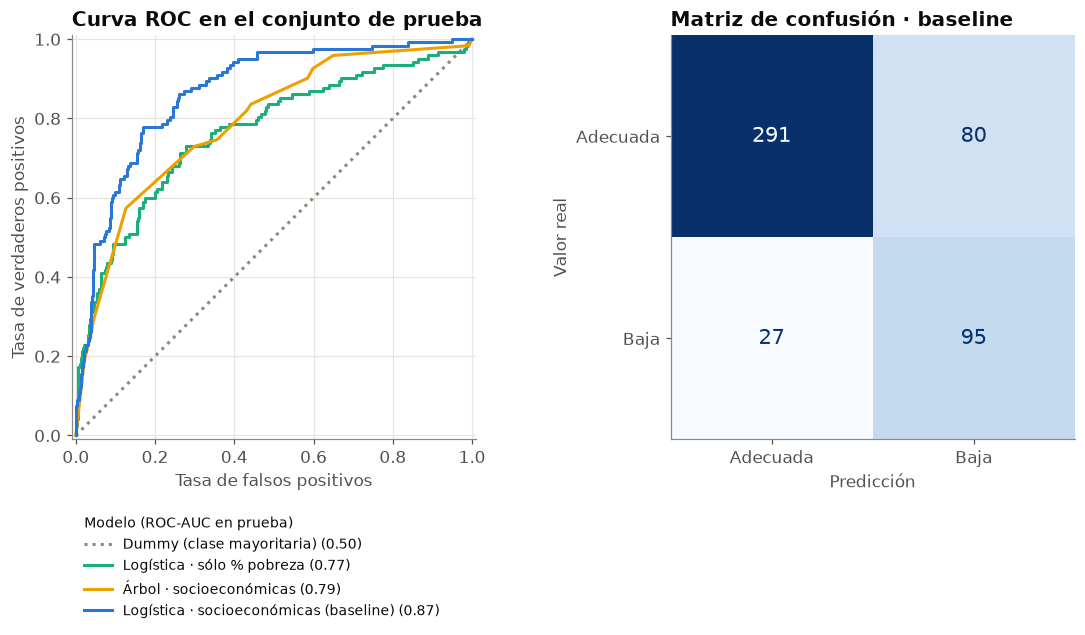

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), gridspec_kw={"width_ratios": [1, 1]})

ax = axes[0]
curvas = [
    (("Sólo % pobreza", "Dummy (clase mayoritaria)"), "Dummy (clase mayoritaria)", TINTA_3, ":"),
    (("Sólo % pobreza", "Regresión logística"), "Logística · sólo % pobreza", AQUA, "-"),
    (("Socioeconómicas", "Árbol de decisión (prof. 4)"), "Árbol · socioeconómicas", AMARILLO, "-"),
    (BASE, "Logística · socioeconómicas (baseline)", AZUL, "-"),
]
for clave, etiqueta, color, estilo in curvas:
    cols = CONJUNTOS[clave[0]]
    proba = ajustados[clave].predict_proba(datos.loc[idx_test, cols])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, linestyle=estilo, linewidth=2,
            label=f"{etiqueta} ({roc_auc_score(y_test, proba):.2f})")
ax.set_title("Curva ROC en el conjunto de prueba")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16), fontsize=9, title="Modelo (ROC-AUC en prueba)",
          title_fontsize=9, alignment="left")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.set_aspect("equal")

ax = axes[1]
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_base, display_labels=["Adecuada", "Baja"], cmap="Blues", colorbar=False, ax=ax,
    text_kw={"fontsize": 14},
)
ax.grid(False)
ax.set_title("Matriz de confusión · baseline")
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
fig.tight_layout(w_pad=4)
guardar(fig, "06_baseline_roc_confusion")
plt.show()

### 3.5 ¿Qué aprendió el modelo? Coeficientes de la logística

Los coeficientes están sobre variables estandarizadas, así que son comparables entre sí. Un valor positivo aumenta la probabilidad de baja accesibilidad. **Ojo:** varias variables están muy correlacionadas (por ejemplo `escolaridad` y `pct_rezago_educativo`), así que algunos signos pueden salir al revés de lo intuitivo. Por eso conviene la selección de variables del apartado de predictores.

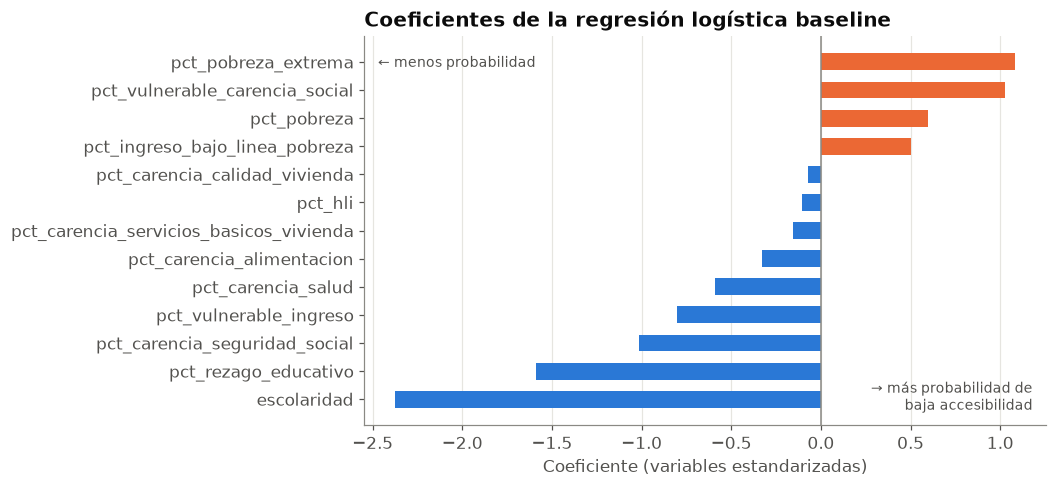

,coef
escolaridad,-2.37
pct_rezago_educativo,-1.59
pct_carencia_seguridad_social,-1.01
pct_vulnerable_ingreso,-0.80
pct_carencia_salud,-0.59
pct_carencia_alimentacion,-0.33
pct_carencia_servicios_basicos_vivienda,-0.16
pct_hli,-0.11
pct_carencia_calidad_vivienda,-0.07
pct_ingreso_bajo_linea_pobreza,0.50


In [30]:
coefs = pd.Series(modelo_base[-1].coef_[0], index=CONJUNTOS[BASE[0]]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(coefs.index, coefs.values, color=[NARANJA if v > 0 else AZUL for v in coefs.values], height=0.6)
ax.axvline(0, color=TINTA_3, linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente (variables estandarizadas)")
ax.set_title("Coeficientes de la regresión logística baseline")
ax.text(0.98, 0.04, "→ más probabilidad de\nbaja accesibilidad", transform=ax.transAxes, ha="right", color=TINTA_2, fontsize=9)
ax.text(0.02, 0.92, "← menos probabilidad", transform=ax.transAxes, ha="left", color=TINTA_2, fontsize=9)
guardar(fig, "07_coeficientes_logistica")
plt.show()
coefs.round(2).to_frame("coef")

Como contraste, las importancias del árbol cuando sí se le da la población: el tamaño del municipio es la variable que más usa.

In [31]:
arbol = ajustados[("Socioeconómicas + log población", "Árbol de decisión (prof. 4)")]
pd.Series(arbol.feature_importances_, index=CONJUNTOS["Socioeconómicas + log población"]).sort_values(ascending=False).head(6).round(3).to_frame("importancia")

,importancia
log_pob,0.502
pct_carencia_servicios_basicos_vivienda,0.317
escolaridad,0.071
pct_carencia_seguridad_social,0.035
pct_pobreza,0.027
pct_carencia_salud,0.016


### 3.6 Comparación de modelos

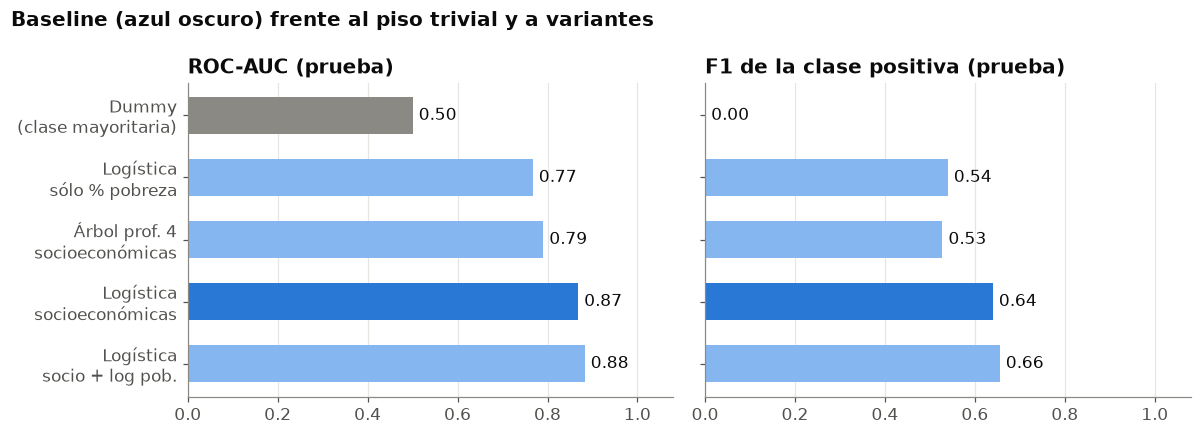

In [32]:
orden = [
    ("—", "Dummy (clase mayoritaria)", "Dummy\n(clase mayoritaria)"),
    ("Sólo % pobreza", "Regresión logística", "Logística\nsólo % pobreza"),
    ("Socioeconómicas", "Árbol de decisión (prof. 4)", "Árbol prof. 4\nsocioeconómicas"),
    ("Socioeconómicas", "Regresión logística", "Logística\nsocioeconómicas"),
    ("Socioeconómicas + log población", "Regresión logística", "Logística\nsocio + log pob."),
]
sel = pd.concat([tabla[(tabla["variables"] == v) & (tabla["modelo"] == m)].assign(etq=e) for v, m, e in orden])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metrica, titulo in [(axes[0], "Prueba ROC-AUC", "ROC-AUC (prueba)"), (axes[1], "Prueba F1", "F1 de la clase positiva (prueba)")]:
    colores_b = [TINTA_3, "#86b6ef", "#86b6ef", AZUL, "#86b6ef"]
    barras = ax.barh(sel["etq"], sel[metrica], color=colores_b, height=0.6)
    ax.bar_label(barras, labels=[f"{v:.2f}" for v in sel[metrica]], padding=4, color=TINTA)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
axes[0].invert_yaxis()
fig.suptitle("Baseline (azul oscuro) frente al piso trivial y a variantes", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
guardar(fig, "08_comparacion_modelos")
plt.show()

### 3.7 Robustez

**a) Validación por entidad.** Ya está en la tabla (columna "Por entidad ROC-AUC"): evaluar en estados no vistos baja el AUC de la logística de ≈0.86 a ≈0.83. Hay algo de dependencia geográfica, pero el modelo no colapsa.

**b) Sensibilidad al umbral de la variable objetivo.** Se repite el baseline con otros umbrales del IA.

In [33]:
filas = []
for u in [0.1, 0.2, 0.33, 0.5]:
    y_u = (datos["ia"] < u).astype(int)
    m = modelos()["Regresión logística"]
    cv = cross_validate(m, datos[SOCIO], y_u, cv=cv_estrat, scoring=["roc_auc", "f1"])
    filas.append({"umbral IA": u, "% positivos": y_u.mean() * 100,
                  "CV ROC-AUC": cv["test_roc_auc"].mean(), "CV F1": cv["test_f1"].mean()})
pd.DataFrame(filas).round(3)

,umbral IA,% positivos,CV ROC-AUC,CV F1
0,0.10,16.234,0.857,0.528
1,0.20,24.756,0.858,0.633
2,0.33,36.404,0.841,0.692
3,0.50,50.528,0.838,0.755


**c) Versión de regresión (IA continuo).** Como alternativa al objetivo binario: una regresión lineal sobre el IA frente a predecir siempre la media.

In [34]:
filas = []
for nombre_x, cols in CONJUNTOS.items():
    for nombre_m, m in {"Dummy (media)": DummyRegressor(),
                        "Regresión lineal": Pipeline([("escala", StandardScaler()), ("modelo", LinearRegression())])}.items():
        if nombre_m.startswith("Dummy") and nombre_x != "Sólo % pobreza":
            continue
        m.fit(datos.loc[idx_train, cols], datos.loc[idx_train, "ia"])
        pred = m.predict(datos.loc[idx_test, cols])
        filas.append({"variables": "—" if nombre_m.startswith("Dummy") else nombre_x, "modelo": nombre_m,
                      "R² prueba": r2_score(datos.loc[idx_test, "ia"], pred),
                      "MAE prueba": mean_absolute_error(datos.loc[idx_test, "ia"], pred)})
pd.DataFrame(filas).round(3)

,variables,modelo,R² prueba,MAE prueba
0,—,Dummy (media),-0.002,0.371
1,Sólo % pobreza,Regresión lineal,0.217,0.310
2,Socioeconómicas,Regresión lineal,0.437,0.264
3,Socioeconómicas + log población,Regresión lineal,0.462,0.254


## 4. Conclusiones del baseline

- **El problema sí se puede aprender.** Con variables socioeconómicas, la regresión logística alcanza ROC-AUC ≈0.87 en prueba (0.86 ± 0.03 en validación cruzada), frente a 0.50 del modelo trivial. El *recall* de la clase positiva es ≈0.78: detecta 4 de cada 5 municipios con baja accesibilidad.
- **La pobreza sola ya explica bastante** (AUC ≈0.77 sólo con `pct_pobreza`). Agregar las carencias y la escolaridad sube el AUC a ≈0.87.
- **El tamaño de población aporta poco una vez que están las variables socioeconómicas** (0.87 → 0.88), aunque en el árbol es la variable más importante. Parte de la señal de pobreza es, en realidad, señal de ruralidad.
- **El árbol simple queda por debajo de la logística.** Los ensambles (Random Forest, Gradient Boosting) con ajuste de hiperparámetros deberían cerrar esa brecha.
- **La precisión es el punto débil** (≈0.54): hay muchos falsos positivos, municipios pobres que sí tienen servicios.

### Cambios previstos para el reporte final

1. Usar los predictores que salgan del apartado de selección de variables, para quitar la colinealidad (signos contraintuitivos en los coeficientes).
2. Random Forest y Gradient Boosting con `GridSearchCV` (profundidad, número de árboles, `class_weight`), comparando contra este baseline.
3. Ajustar el umbral de decisión de la probabilidad para equilibrar precisión y *recall*.
4. Validación agrupada por entidad como esquema principal, o agregar la región como variable.
5. Probar las tasas con suavizado bayesiano empírico, o ponderar por población, para reducir el ruido de los municipios pequeños.
6. **Datos adicionales que ayudarían:** población de 0–4 años (ITER) para las guarderías; consultorios públicos y unidades de salud (DENUE 621112/621114, CLUES); tiendas de abarrotes y mercados; distancia a la cabecera o a la localidad urbana más cercana.